,applicant_country,patent_count
0,US,258
1,,137
2,DE,47
3,JP,36
4,KR,28
5,CN,22
6,PL,18
7,GB,15
8,DK,11
9,IL,11


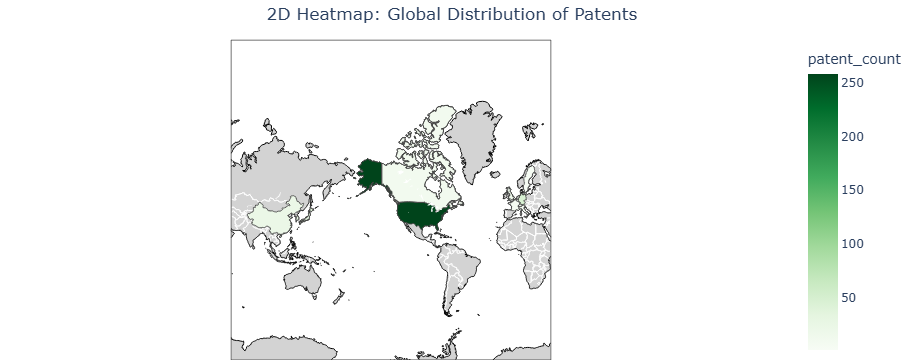

In [11]:
%run setup.ipynb
%run key_words.ipynb

def get_patents_count_by_applicant_country():
    """Count of patent applications grouped by the applicant's country."""
    
    # Clean spaces from CPC codes and build the LIKE conditions
    cpc_conditions = " OR ".join([
        f"REPLACE(t224.cpc_class_symbol, ' ', '') LIKE '{code.replace(' ', '')}%'" 
        for code in CPC_CODES
    ])
    
    query_string = f"""
    SELECT 
        t206.person_ctry_code AS applicant_country,
        COUNT(DISTINCT t201.appln_id) AS patent_count
    FROM tls201_appln t201
    INNER JOIN tls224_appln_cpc t224 ON t201.appln_id = t224.appln_id
    INNER JOIN tls207_pers_appln t207 ON t201.appln_id = t207.appln_id
    INNER JOIN tls206_person t206 ON t207.person_id = t206.person_id
    WHERE ({cpc_conditions})
    --  AND t207.appln_seq_nr Optional: limits to the primary applicant to avoid duplicate counting per application if there are multiple co-applicants
    GROUP BY t206.person_ctry_code
    ORDER BY patent_count DESC
    """
    
    df = pd.read_sql(text(query_string), db.bind)
    return df

# 1. Retrieve data grouped by filing authority from your function
df_countries = get_patents_count_by_applicant_country()

display(df_countries)

# 2. Quick mapping dictionary from ISO-2 (PATSTAT) to ISO-3 (required by Plotly)
iso2_to_iso3 = {
    'US': 'USA', 'DE': 'DEU', 'JP': 'JPN', 'CN': 'CHN', 
    'GB': 'GBR', 'FR': 'FRA', 'KR': 'KOR', 'IT': 'ITA',
    'NL': 'NLD', 'SE': 'SWE', 'CH': 'CHE', 'CA': 'CAN'
    # You can add other countries of interest here
}

# Add a column with the ISO-3 format
df_countries['iso3'] = df_countries['applicant_country'].map(iso2_to_iso3)

# 3. Create the 2D heatmap using a flat Mercator projection
fig = px.choropleth(
    df_countries.dropna(subset=['iso3']), # Temporarily excludes EP/WO since they are organizations, not single country polygons
    locations="iso3",
    locationmode="ISO-3",
    color="patent_count",
    hover_name="applicant_country",
    color_continuous_scale="Greens",     # Heatmap color scale
    projection="mercator"                 # <-- This renders a flat 2D map
)

# 4. Customize map styling
fig.update_geos(
    showcoastlines=True,
    coastlinecolor="Black",
    showland=True,
    landcolor="lightgray",
    showcountries=True,
    countrycolor="white"
)

fig.update_layout(
    title_text="2D Heatmap: Global Distribution of Patents",
    title_x=0.5,
    margin={"r": 0, "t": 40, "l": 0, "b": 0}
)

fig.show()